# 08 — Gradyan Artırma (GBM) ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Gradyan artırma, karar ağaçlarını **ardışık** olarak kurar: her yeni ağaç, o ana
dek kurulmuş topluluğun hatalarını (kalıntılarını) düzeltmeye çalışır. Bagging'den
(Rastgele Orman) temel farkı budur; ağaçlar bağımsız değil, zincirleme öğrenir. Yüksek
doğruluk verir; buna karşılık eğitimi yavaştır ve öğrenme oranına duyarlıdır. Model
200 ağaç ve **0,3** öğrenme oranıyla (doğrulama kümesiyle seçildi) kurulmuştur.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
reg_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.3, random_state=42)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1822
   MSE: 0.0685
  RMSE: 0.2618
    R2: 0.7257
   AUC: 0.9728


In [3]:
o.reg_grafikleri(yr_te, y_pred, "Gradyan Artırma (GBM)", "gbm")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\gbm_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = GradientBoostingClassifier(n_estimators=200, learning_rate=0.3, random_state=42)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9236
   BalancedAcc: 0.9234
      F1_macro: 0.9235
   F1_weighted: 0.9235

              precision    recall  f1-score   support

  Yangın Yok      0.921     0.930     0.925       653
      Yangın      0.926     0.917     0.922       629

    accuracy                          0.924      1282
   macro avg      0.924     0.923     0.924      1282
weighted avg      0.924     0.924     0.924      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1822 |   0.4998 |    0.3931 | -0.2109 (iyi)
     MSE |   0.0685 |   0.2499 |    0.1978 | -0.1292 (iyi)
    RMSE |   0.2618 |   0.4999 |    0.4447 | -0.1829 (iyi)
      R2 |   0.7257 |  -0.0000 |    0.2086 | +0.5172 (iyi)
     AUC |   0.9728 |   0.5000 |    0.6982 | +0.2746 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9236 |   0.5094 |    0.6934 | +0.2301
     BalancedAcc |  0.9234 |   0.5000 |    0.6982 | +0.2253
        F1_macro |  0.9235 |   0.3375 |    0.6748 | +0.2487
     F1_weighted |  0.9235 |   0.3438 |    0.6733 | +0.2502
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "Gradyan Artırma (GBM)", "gbm")

Gradyan Artırma (GBM) — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   607     46
      Yangın |    52    577


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\gbm_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### Özellik Önemleri ve Öğrenme Oranının Etkisi

Öğrenme oranı, her ağacın topluluğa yaptığı katkıyı ölçekler. Düşük oran daha yavaş
ama daha güvenli öğrenme demektir; yüksek oran hızlı yakınsar, ancak aşırı öğrenme
riski taşır. Ağaç sayısı 200'de sabit tutularak oran taranmıştır.

In [7]:
o.ozellik_onem_grafigi(clf.feature_importances_, "GBM", "gbm")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\gbm_onem.png'

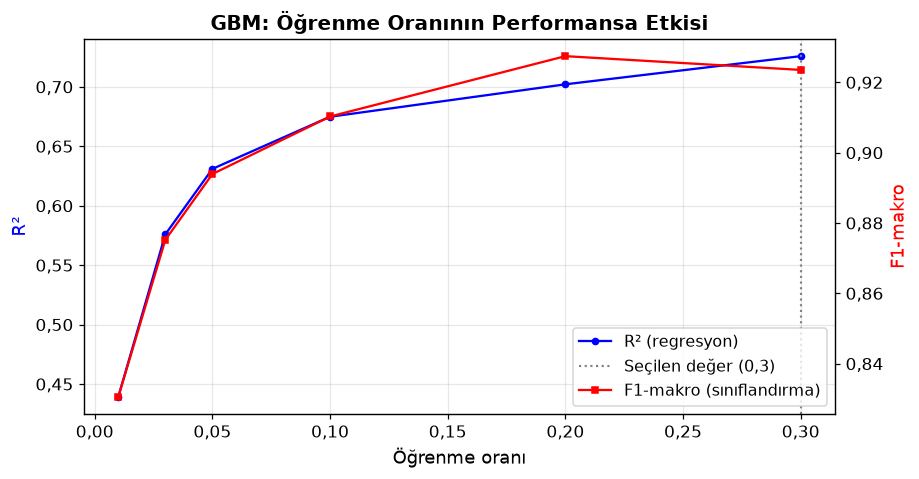

Tarama: [(0.01, 0.4391, 0.8305), (0.03, 0.5759, 0.8752), (0.05, 0.6309, 0.8939), (0.1, 0.6748, 0.9103), (0.2, 0.7021, 0.9274), (0.3, 0.7257, 0.9235)]
En yüksek R²: 0.7257 (0.3) · en yüksek F1-makro: 0.9274 (0.2)


In [8]:
degerler = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3]
r2_list, f1_list = [], []
for lr_ in degerler:
    r = GradientBoostingRegressor(n_estimators=200, learning_rate=lr_, random_state=42).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = GradientBoostingClassifier(n_estimators=200, learning_rate=lr_, random_state=42).fit(X_tr, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(0.3, color="gray", ls=":", lw=1.4, label="Seçilen değer (0,3)")
ax1.set_xlabel("Öğrenme oranı")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.plot(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("GBM: Öğrenme Oranının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "gbm_lr_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [9]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = GradientBoostingRegressor(n_estimators=200, learning_rate=0.3, random_state=42).fit(Xa, yra).predict(Xb)
    c_tahmin = GradientBoostingClassifier(n_estimators=200, learning_rate=0.3, random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² -0.0434 · F1-makro 0.7122


  kat 2: eğitim  4170 · sınama   958 · R² -0.0835 · F1-makro 0.6553


  kat 3: eğitim  4114 · sınama  1014 · R² +0.4654 · F1-makro 0.8287


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4001 · F1-makro 0.8488


  kat 5: eğitim  4150 · sınama   978 · R² +0.3655 · F1-makro 0.7950
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.2208 ± 0.2347
  F1-makro: 0.7680 ± 0.0732


In [10]:
o.sonuc_kaydet("gbm", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\gbm.json


{'algoritma': 'gbm',
 'regresyon': {'MAE': 0.18216521586574883,
  'MSE': 0.06854094669105917,
  'RMSE': 0.26180325951190747,
  'R2': 0.7257400943438834,
  'AUC': 0.9728074169115516},
 'siniflandirma': {'Accuracy': 0.9235569422776911,
  'BalancedAcc': 0.9234424948324598,
  'F1_macro': 0.923515058832697,
  'F1_weighted': 0.9235485655886922},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [-0.043426606995056405,
    -0.08347254869021126,
    0.4654498107445434,
    0.40011519852477706,
    0.365524889061288],
   'F1_macro': [0.7121641546526868,
    0.6552732862474744,
    0.8286733981050661,
    0.8487785781396806,
    0.7950072313399987],
   'R2_ort': 0.22083814852906816,
   'R2_std': 0.23467008343081516,
   'F1_ort': 0.7679793296969812,
   'F1_std': 0.07315843348694985},
  'duyarlilik': {'degerler': [0.01, 0.03, 0.05, 0.1, 0.2, 0.3],
   'R2': [0.43911953892437894,
    0.5758622660344483,
    0.6309304396882316,
    0.6747763810362668,
    0.70205232588062,
    0.7257400943438834],
 